# **Proposta M1 — Projeto Final de Visão Computacional**
# Tema 3: Analisar lesões de pele com incerteza


**Aluna:** Alice De Muylder Oliveira

**Disciplina:** Visão Computacional — Projeto Final

**Etapa:** M1 — Proposta (documentação + notebook de exploração inicial)

# Tema escolhido e motivação 

Escolhi o Tema 3, análise de lesões de pele, por combinar segmentação, classificação e explicabilidade em 
um pipeline coerente, sobre um dataset amplamente documentado e com forte relevância ética, área de 
particular interesse pessoal dentro de ciência de dados e aprendizado de máquina.

# Problema em uma frase 

Dado uma imagem dermatoscópica, o sistema deve delimitar a região da lesão, classificar seu tipo entre as 
categorias diagnósticas conhecidas, e indicar visualmente em quais regiões da imagem baseou sua decisão.

# Entrada e saída esperadas 

**Entrada:** imagem dermatoscópica RGB de uma lesão de pele. 

**Saídas:**

• Máscara binária de segmentação delimitando a lesão. 

• Classe prevista entre as categorias diagnósticas do dataset (ex.: nevo melanocítico, melanoma, carcinoma basocelular, etc.). 


• Mapa de atenção (Grad-CAM) indicando as regiões mais relevantes para a decisão do classificador.

# Dataset: origem, licença e organização 

O dataset vem do ISIC Archive, o maior acervo público de imagens dermatoscópicas do mundo, mantido  pela International Skin Imaging Collaboration. É a fonte usada pela maioria dos trabalhos de ML em  dermatologia. 

Como o Archive é enorme, este projeto usa um recorte específico dele: o ISIC 2018 Challenge, uma competição que organizou um subconjunto de imagens em dois grupos, cada um com um tipo diferente de anotação sobre praticamente as mesmas fotos: 

• **Grupo 1** — anotação de contorno: cada imagem vem acompanhada de uma máscara indicando exatamente onde está a lesão (usado para a tarefa de segmentação). 

• **Grupo 2** — anotação de diagnóstico: cada imagem vem com um rótulo de classe entre 7 categorias diagnósticas (ex.: melanoma, nevo, carcinoma). Esse grupo é conhecido popularmente pelo nome HAM10000 — é o mesmo conjunto de imagens, só que com outro apelido. Esse grupo não tem  máscara, só o rótulo. 

Como as imagens dos dois grupos se sobrepõem bastante, dá para juntar as duas anotações (contorno + diagnóstico) para boa parte do dataset, que é exatamente o que o pipeline deste projeto (segmentar, depois classificar) precisa. 

**Licença:** CC BY-NC 4.0,  uso não comercial, com atribuição, compatível com a finalidade educacional do projeto.

**Organização:**

• ~10.000 imagens dermatoscópicas rotuladas. 

• Metadados por imagem: idade, sexo, localização anatômica, método de confirmação diagnóstica, e um identificador de lesão (lesion_id), importante para evitar vazamento entre imagens da mesma lesão. 

• Máscaras de contorno disponíveis apenas para o subconjunto de segmentação (Grupo 1), dentro do mesmo Archive. 

# Tarefas e métricas candidatas 

**Tarefa**                     |            **Métrica**

Segmentação da lesão           |        Dice / IoU 

Classificação diagnóstica      |        Macro-F1, Recall da classe mais crítica (melanoma) 

Explicabilidade                |        Inspeção qualitativa dos mapas Grad-CAM em acertos e erros


# Três riscos iniciais e plano de redução 

**1. Desbalanceamento de classes. Melanoma** (a classe clinicamente mais crítica) é minoria no dataset frente a lesões benignas. 

→ Redução: usar perda ponderada por classe e reportar recall por classe, não só acurácia global. 


**2. Vazamento de dados entre treino e teste.** Algumas lesões têm múltiplas imagens associadas ao mesmo identificador de lesão. 

→ Redução: fazer o split treino/validação/teste por identificador de lesão (lesion_id), garantindo que todas as imagens de uma mesma lesão fiquem no mesmo conjunto. 


**3. Viés de representação nos dados.** Datasets dermatoscópicos públicos são conhecidos por sub representar tons de pele mais escuros, o que pode limitar a generalização do modelo. 

→ Redução: reconhecer explicitamente essa limitação no relatório final, evitar conclusões que extrapolem além dos metadados disponíveis, e reforçar que o sistema tem finalidade educacional, não substituindo avaliação clínica.

# Exploração Inicial — Lesões de Pele (ISIC 2018 / HAM10000)

**Objetivo deste notebook:** conhecer o dataset antes de qualquer treinamento, quantidade e formato das
imagens, distribuição das classes diagnósticas, metadados demográficos, sobreposição entre o grupo de
segmentação e o grupo de classificação, e uma hipótese de split treino/validação/teste que respeite o
`lesion_id` (para evitar vazamento de dados).

## 0. Estrutura de pastas esperada

Este notebook assume que os dados do **ISIC 2018 Challenge / HAM10000** foram baixados e colocados assim:

```
data/
├── metadata/
│   └── HAM10000_metadata.csv          # Grupo 2 — rótulos de diagnóstico (dx, idade, sexo, localização, lesion_id)
├── images/                             # imagens dermatoscópicas (Grupo 2 — classificação)
│   └── ...                             # .jpg podem estar direto aqui ou em subpastas (ex.: ISIC2018_Task3_Training_Input/)
└── masks/                              # máscaras de contorno (Grupo 1 — segmentação)
    └── ...                             # .png podem estar direto aqui ou em subpastas (ex.: ISIC2018_Task1_Training_GroundTruth/)
```

`IMAGES_DIR` e `MASKS_DIR` só precisam apontar para a pasta-mãe (`data/images`, `data/masks`) — a busca por
arquivos abaixo é **recursiva** (`rglob`), então não importa quantos níveis de subpasta existam por baixo
(é comum o ZIP baixado do ISIC vir com uma subpasta extra, às vezes até duplicada, com o nome do challenge).

Ajuste os caminhos na célula abaixo caso sua organização local seja diferente. Os dados podem ser obtidos em:
- ISIC Archive: https://www.isic-archive.com/
- ISIC 2018 Challenge (Task 1 — segmentação, Task 3 — classificação): https://challenge.isic-archive.com/data/#2018

Todas as células abaixo verificam se os arquivos existem antes de rodar, então o notebook não quebra caso
os dados ainda não estejam baixados — ele só avisa o que falta.


In [14]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("data")
METADATA_PATH = DATA_DIR / "metadata" / "HAM10000_metadata.csv"
IMAGES_DIR = DATA_DIR / "images"        # Grupo 2 — classificação
MASKS_DIR = DATA_DIR / "masks"          # Grupo 1 — segmentação

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 100


def build_file_index(root_dir, extensions):
    """Busca recursivamente (rglob) por arquivos com as extensões dadas dentro de root_dir
    e retorna um dict {nome_sem_extensao: caminho}. Isso evita depender de saber o nome exato
    de subpastas internas (ex.: ISIC2018_Task3_Training_Input), que variam conforme o download
    e foi a causa das imagens não aparecerem nas células abaixo."""
    index = {}
    if not root_dir.exists():
        return index
    for ext in extensions:
        for path in root_dir.rglob(f"*{ext}"):
            index[path.stem] = path
    return index


print("Metadados encontrados:", METADATA_PATH.exists())
print("Pasta de imagens encontrada:", IMAGES_DIR.exists())
print("Pasta de máscaras encontrada:", MASKS_DIR.exists())

IMAGE_INDEX = build_file_index(IMAGES_DIR, [".jpg", ".jpeg", ".png"])
MASK_INDEX = build_file_index(MASKS_DIR, [".png"])

print(f"Imagens encontradas (busca recursiva): {len(IMAGE_INDEX)}")
print(f"Máscaras encontradas (busca recursiva): {len(MASK_INDEX)}")

Metadados encontrados: True
Pasta de imagens encontrada: True
Pasta de máscaras encontrada: True
Imagens encontradas (busca recursiva): 10015
Máscaras encontradas (busca recursiva): 2594


## 1. Metadados (Grupo 2 — diagnóstico)

O arquivo `HAM10000_metadata.csv` traz um registro por imagem, com o rótulo diagnóstico (`dx`), o método de
confirmação (`dx_type`), idade, sexo, localização anatômica e o `lesion_id` — o identificador que agrupa
várias fotos da mesma lesão.

In [15]:
if METADATA_PATH.exists():
    meta = pd.read_csv(METADATA_PATH)
    print(f"Total de registros: {len(meta)}")
    print(f"Total de lesões únicas (lesion_id): {meta['lesion_id'].nunique()}")
    display(meta.head())
else:
    meta = None
    print(f"Arquivo não encontrado em {METADATA_PATH}. Baixe o CSV de metadados do ISIC/HAM10000 "
          f"e ajuste METADATA_PATH acima antes de continuar.")

Total de registros: 10015
Total de lesões únicas (lesion_id): 7470


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [16]:
if meta is not None:
    print("Colunas disponíveis:", list(meta.columns))
    print()
    print("Valores nulos por coluna:")
    print(meta.isnull().sum())

Colunas disponíveis: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Valores nulos por coluna:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64


## 2. Contagem de classes diagnósticas

As 7 categorias diagnósticas do dataset (coluna `dx`). Essa contagem já antecipa o **risco de
desbalanceamento** apontado na proposta — melanoma (`mel`) costuma ser bem menos frequente que classes
benignas como nevo melanocítico (`nv`).

,descrição,contagem,percentual
dx,,,
nv,Nevo melanocítico (benigno),6705,66.9
mel,Melanoma (maligno),1113,11.1
bkl,Ceratose benigna,1099,11.0
bcc,Carcinoma basocelular (maligno),514,5.1
akiec,Ceratose actínica / Bowen,327,3.3
vasc,Lesão vascular,142,1.4
df,Dermatofibroma,115,1.1


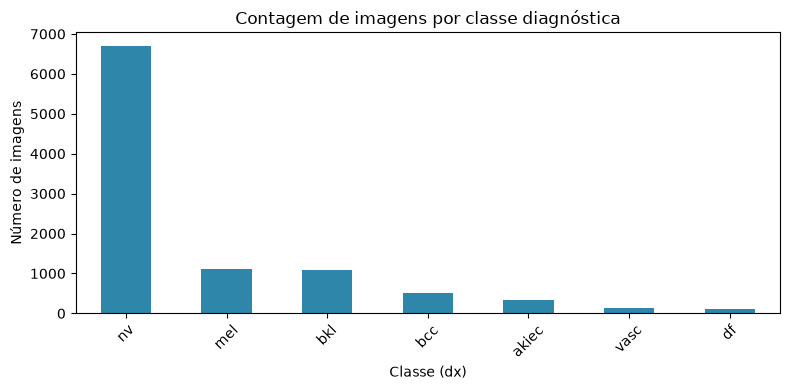


Classe majoritária: nv (6705 imagens, 66.9%)
Classe minoritária: df (115 imagens, 1.1%)
Razão majoritária/minoritária: 58.3x


In [17]:
DX_LABELS = {
    "nv": "Nevo melanocítico (benigno)",
    "mel": "Melanoma (maligno)",
    "bkl": "Ceratose benigna",
    "bcc": "Carcinoma basocelular (maligno)",
    "akiec": "Ceratose actínica / Bowen",
    "vasc": "Lesão vascular",
    "df": "Dermatofibroma",
}

if meta is not None:
    counts = meta["dx"].value_counts()
    pct = (counts / counts.sum() * 100).round(1)

    summary = pd.DataFrame({
        "descrição": [DX_LABELS.get(c, c) for c in counts.index],
        "contagem": counts.values,
        "percentual": pct.values,
    }, index=counts.index)
    display(summary)

    fig, ax = plt.subplots(figsize=(8, 4))
    counts.plot(kind="bar", ax=ax, color="#2E86AB")
    ax.set_title("Contagem de imagens por classe diagnóstica")
    ax.set_xlabel("Classe (dx)")
    ax.set_ylabel("Número de imagens")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print(f"\nClasse majoritária: {counts.idxmax()} ({counts.max()} imagens, {pct.max()}%)")
    print(f"Classe minoritária: {counts.idxmin()} ({counts.min()} imagens, {pct.min()}%)")
    print(f"Razão majoritária/minoritária: {counts.max() / counts.min():.1f}x")

## 3. Amostras de imagens

Uma amostra visual de algumas imagens por classe, para ter uma noção qualitativa de como as lesões
aparecem — variação de zoom, iluminação, presença de pelos, réguas de medição, etc.

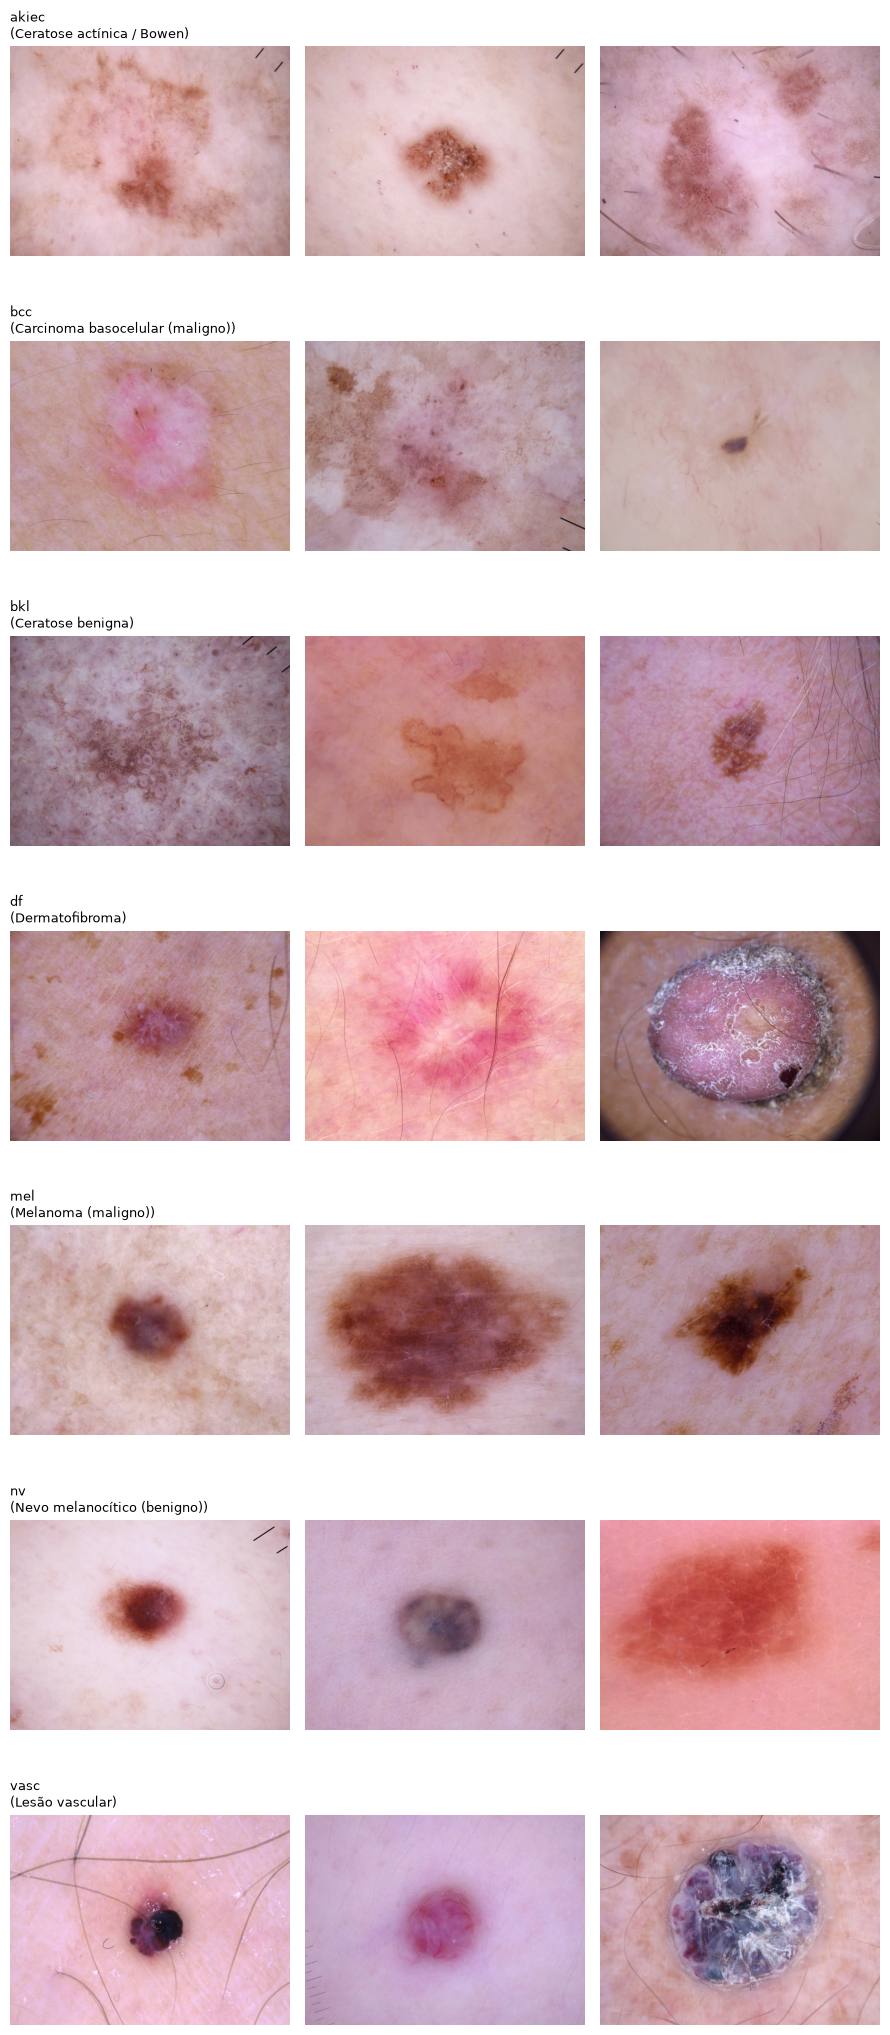

In [18]:
def show_samples_per_class(meta, image_index, n_per_class=3, seed=RANDOM_SEED):
    if meta is None or not image_index:
        print("Metadados ou índice de imagens indisponíveis — pulando visualização de amostras.")
        return

    classes = sorted(meta["dx"].unique())
    fig, axes = plt.subplots(len(classes), n_per_class, figsize=(3 * n_per_class, 3 * len(classes)))

    rng = np.random.default_rng(seed)
    missing = []
    for i, cls in enumerate(classes):
        subset = meta[meta["dx"] == cls]
        sample_ids = rng.choice(subset["image_id"].values, size=min(n_per_class, len(subset)), replace=False)
        for j in range(n_per_class):
            ax = axes[i, j] if len(classes) > 1 else axes[j]
            ax.axis("off")
            if j < len(sample_ids):
                img_path = image_index.get(sample_ids[j])
                if img_path is not None:
                    img = Image.open(img_path)
                    ax.imshow(img)
                else:
                    missing.append(sample_ids[j])
                    ax.text(0.5, 0.5, "imagem\nnão encontrada", ha="center", va="center",
                            fontsize=8, color="red")
                if j == 0:
                    ax.set_title(f"{cls}\n({DX_LABELS.get(cls, cls)})", fontsize=9, loc="left")
    plt.tight_layout()
    plt.show()

    if missing:
        print(f"Aviso: {len(missing)} imagem(ns) não encontrada(s) no índice: {missing}")

show_samples_per_class(meta, IMAGE_INDEX)

## 4. Dimensões das imagens

Verificação do tamanho (largura x altura) e modo de cor de uma amostra de imagens, para saber se será
necessário redimensionar/padronizar antes do treinamento.

In [19]:
def check_image_dimensions(image_index, sample_size=200, seed=RANDOM_SEED):
    if not image_index:
        print("Nenhuma imagem encontrada no índice.")
        return None

    all_images = list(image_index.values())

    rng = np.random.default_rng(seed)
    sample_idx = rng.choice(len(all_images), size=min(sample_size, len(all_images)), replace=False)
    sample = [all_images[k] for k in sample_idx]

    dims = []
    modes = []
    for path in sample:
        with Image.open(path) as img:
            dims.append(img.size)  # (largura, altura)
            modes.append(img.mode)

    dims_df = pd.DataFrame(dims, columns=["largura", "altura"])
    print(f"Amostra de {len(sample)} imagens (de um total de {len(all_images)})")
    print("\nDimensões únicas encontradas:")
    print(dims_df.value_counts())
    print("\nModos de cor encontrados:", set(modes))
    return dims_df

dims_df = check_image_dimensions(IMAGE_INDEX)

Amostra de 200 imagens (de um total de 10015)

Dimensões únicas encontradas:
largura  altura
600      450       200
Name: count, dtype: int64

Modos de cor encontrados: {'RGB'}


## 5. Metadados demográficos

Distribuição de idade, sexo e localização anatômica das lesões — relevante para o risco de **viés de
representação** apontado na proposta (ex.: verificar se há concentração forte em determinadas faixas
etárias ou localizações que possa limitar a generalização).

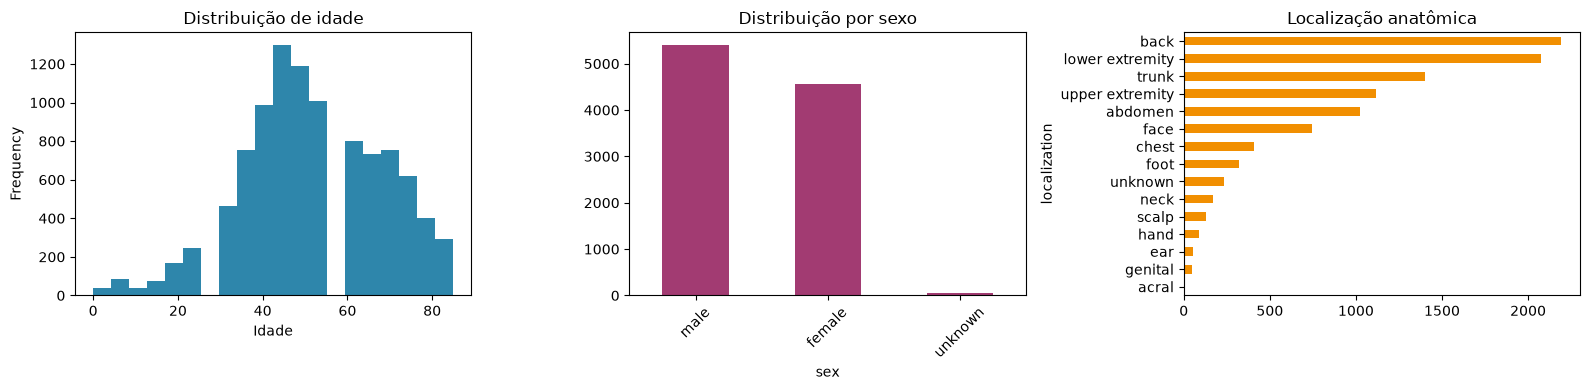

Método de confirmação diagnóstica (dx_type):
dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69
Name: count, dtype: int64


In [20]:
if meta is not None:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    meta["age"].dropna().plot(kind="hist", bins=20, ax=axes[0], color="#2E86AB")
    axes[0].set_title("Distribuição de idade")
    axes[0].set_xlabel("Idade")

    meta["sex"].value_counts().plot(kind="bar", ax=axes[1], color="#A23B72")
    axes[1].set_title("Distribuição por sexo")
    axes[1].tick_params(axis="x", rotation=45)

    meta["localization"].value_counts().plot(kind="barh", ax=axes[2], color="#F18F01")
    axes[2].set_title("Localização anatômica")
    axes[2].invert_yaxis()

    plt.tight_layout()
    plt.show()

    print("Método de confirmação diagnóstica (dx_type):")
    print(meta["dx_type"].value_counts())

## 6. Sobreposição entre Grupo 1 (segmentação) e Grupo 2 (classificação)

A proposta assume que dá para juntar as máscaras de contorno (Grupo 1) com os rótulos de diagnóstico
(Grupo 2) para boa parte do dataset, já que as imagens se sobrepõem. Aqui verificamos o tamanho real dessa
interseção.

In [21]:
def check_group_overlap(meta, mask_index):
    if meta is None or not mask_index:
        print("Metadados ou índice de máscaras indisponíveis — pulando checagem de sobreposição.")
        return

    # Formato típico do ISIC: ISIC_0024306_segmentation.png -> extrai o image_id
    mask_ids = {stem.replace("_segmentation", "") for stem in mask_index.keys()}
    classification_ids = set(meta["image_id"])

    overlap = mask_ids & classification_ids
    only_masks = mask_ids - classification_ids
    only_labels = classification_ids - mask_ids

    print(f"Imagens com máscara de segmentação: {len(mask_ids)}")
    print(f"Imagens com rótulo de diagnóstico: {len(classification_ids)}")
    print(f"Interseção (têm as duas anotações): {len(overlap)}")
    print(f"Só com máscara (sem rótulo): {len(only_masks)}")
    print(f"Só com rótulo (sem máscara): {len(only_labels)}")
    print(f"\n% do dataset de classificação com máscara disponível: "
          f"{len(overlap) / len(classification_ids) * 100:.1f}%")

check_group_overlap(meta, MASK_INDEX)

Imagens com máscara de segmentação: 2594
Imagens com rótulo de diagnóstico: 10015
Interseção (têm as duas anotações): 0
Só com máscara (sem rótulo): 2594
Só com rótulo (sem máscara): 10015

% do dataset de classificação com máscara disponível: 0.0%


## 7. Verificação de `lesion_id` (risco de vazamento)

Quantas lesões têm mais de uma imagem associada. Isso confirma o risco #2 da proposta — se o split for
feito por imagem (e não por lesão), fotos da mesma lesão podem cair em treino e teste ao mesmo tempo,
inflando artificialmente a performance.

Total de lesões únicas: 7470
Lesões com apenas 1 imagem: 5514
Lesões com 2+ imagens: 1956
Máximo de imagens para uma mesma lesão: 6


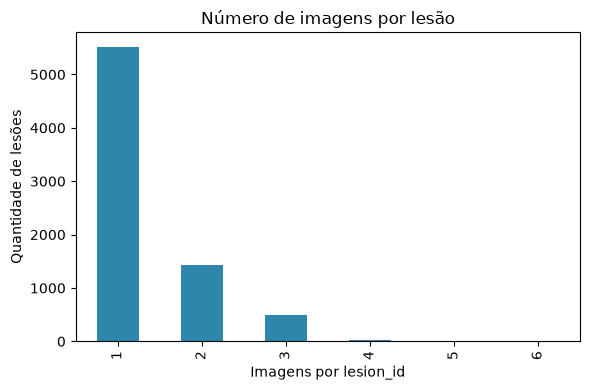

In [22]:
if meta is not None:
    imgs_per_lesion = meta.groupby("lesion_id").size()

    print(f"Total de lesões únicas: {len(imgs_per_lesion)}")
    print(f"Lesões com apenas 1 imagem: {(imgs_per_lesion == 1).sum()}")
    print(f"Lesões com 2+ imagens: {(imgs_per_lesion >= 2).sum()}")
    print(f"Máximo de imagens para uma mesma lesão: {imgs_per_lesion.max()}")

    fig, ax = plt.subplots(figsize=(6, 4))
    imgs_per_lesion.value_counts().sort_index().plot(kind="bar", ax=ax, color="#2E86AB")
    ax.set_title("Número de imagens por lesão")
    ax.set_xlabel("Imagens por lesion_id")
    ax.set_ylabel("Quantidade de lesões")
    plt.tight_layout()
    plt.show()

## 8. Hipótese de split treino / validação / teste

Split proposto: **70% treino / 15% validação / 15% teste**, agrupado por `lesion_id` (nunca por imagem
isolada), para eliminar o vazamento identificado no risco #2. Verificamos também se a proporção de classes
se mantém razoavelmente parecida entre os três conjuntos.

In [23]:
from sklearn.model_selection import GroupShuffleSplit

def grouped_split(meta, group_col="lesion_id", label_col="dx",
                   train_size=0.70, val_size=0.15, seed=RANDOM_SEED):
    if meta is None:
        print("Metadados indisponíveis — pulando split.")
        return None

    groups = meta[group_col]

    # 1ª divisão: treino vs (validação + teste)
    gss1 = GroupShuffleSplit(n_splits=1, train_size=train_size, random_state=seed)
    train_idx, temp_idx = next(gss1.split(meta, groups=groups))

    train_df = meta.iloc[train_idx]
    temp_df = meta.iloc[temp_idx]

    # 2ª divisão: validação vs teste, dentro do restante
    relative_val_size = val_size / (1 - train_size)
    gss2 = GroupShuffleSplit(n_splits=1, train_size=relative_val_size, random_state=seed)
    val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df[group_col]))

    val_df = temp_df.iloc[val_idx]
    test_df = temp_df.iloc[test_idx]

    # Confirma que não há lesion_id compartilhado entre os conjuntos
    assert set(train_df[group_col]) & set(val_df[group_col]) == set()
    assert set(train_df[group_col]) & set(test_df[group_col]) == set()
    assert set(val_df[group_col]) & set(test_df[group_col]) == set()

    print(f"Treino: {len(train_df)} imagens, {train_df[group_col].nunique()} lesões "
          f"({len(train_df) / len(meta) * 100:.1f}%)")
    print(f"Validação: {len(val_df)} imagens, {val_df[group_col].nunique()} lesões "
          f"({len(val_df) / len(meta) * 100:.1f}%)")
    print(f"Teste: {len(test_df)} imagens, {test_df[group_col].nunique()} lesões "
          f"({len(test_df) / len(meta) * 100:.1f}%)")
    print("\nNenhum lesion_id vazou entre os conjuntos (asserts passaram).")

    print("\nDistribuição de classes por conjunto (%):")
    dist = pd.DataFrame({
        "treino": train_df[label_col].value_counts(normalize=True) * 100,
        "validação": val_df[label_col].value_counts(normalize=True) * 100,
        "teste": test_df[label_col].value_counts(normalize=True) * 100,
    }).round(1)
    display(dist)

    return train_df, val_df, test_df

split_result = grouped_split(meta)
if split_result is not None:
    train_df, val_df, test_df = split_result

Treino: 7002 imagens, 5229 lesões (69.9%)
Validação: 1519 imagens, 1120 lesões (15.2%)
Teste: 1494 imagens, 1121 lesões (14.9%)

Nenhum lesion_id vazou entre os conjuntos (asserts passaram).

Distribuição de classes por conjunto (%):


,treino,validação,teste
dx,,,
akiec,3.0,3.8,4.2
bcc,5.4,4.3,4.6
bkl,10.6,13.6,10.2
df,1.3,1.3,0.5
mel,11.0,10.3,12.5
nv,67.4,65.2,66.7
vasc,1.4,1.6,1.4


In [24]:
check_image_dimensions

<function __main__.check_image_dimensions(image_index, sample_size=200, seed=42)>

In [25]:
check_group_overlap

<function __main__.check_group_overlap(meta, mask_index)>

## 9. Conclusões desta exploração inicial

- Tamanho e balanceamento das classes:

Dataset bem desbalanceado. A classe `nv`(nevo/pinta benigna) é 66.9% de tudo (6705 imagens), enquanto `df`
(dermatofibroma) é só 1.1% (115 imagens), 58x menos. O `mel` (melanoma, a mais perigosa) é 11.1% do total. Confirma que vai precisar dar peso maior pra essa classe no treino, como já estava previsto na proposta.

- Dimensões predominantes das imagens: 

Todas as 200 imagens da amostra têm exatamente 600x450 pixels, no modo RGB. Ou seja, o dataset já vem padronizado em tamanho, não é necessário preocupar em redimensionar imagens de tamanhos diferentes.

- % do dataset com segmentação + classificação disponíveis: 

0%. As 2594 imagens com máscara (segmentação) e as 10015 imagens com rótulo(classificação) não têm nenhum ID em comum — são dois conjuntos de imagens completamente separados, não duas anotações da mesma foto.

- Distribuição de idade/sexo/localização — algum viés aparente?: 

A maioria dos diagnósticos foi confirmada por biópsia/histopatologia (`histo`, 5340 casos) ou acompanhamento clínico (`follow_up`, 3704), método mais confiável. Bom sinal de qualidade do rótulo. (Idade/sexo/localização exata está nos gráficos da célula 21, mas nada ali muda o plano do projeto.)

- O split por `lesion_id` manteve as classes proporcionalmente parecidas entre treino/val/teste?: 

Sim. Treino (69.9%), validação (15.2%) e teste (14.9%) ficaram bem próximos do 70/15/15 planejado, sem nenhuma lesão repetida entre os conjuntos, e a proporção de cada classe (`nv`, `mel`, etc.) ficou parecida nos três grupos.